# 📘 Notebook 08: Weight Initialisation, Where Training Starts

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** About **thirty minutes** on an ordinary processor. Deep fully connected networks (10 layers) are used on purpose, because initialisation matters little for shallow ones; With Adam or with shallow networks, PyTorch's default initialisation works well (it is what every earlier notebook used); with deep networks and plain SGD it is not enough, as Section 4 shows.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain why all-**zero** initial weights cannot work
- Watch the **activations** shrink to nothing or explode through a deep network when weights are too small or too large
- Explain **Xavier (Glorot)** and **He (Kaiming)** initialisation and which activation each is designed for
- Show the effect on **training** of a 10-layer network
- Know what PyTorch does by default

> **Prerequisites:** [Notebook 06: Activation Functions](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/06_activation_functions.ipynb).
>
> 🔭 **Why this notebook matters:** initialisation is a hyperparameter most people never set, because frameworks choose well for them. Understanding why their choice works explains one of the main reasons deep networks became trainable after 2010.

## 1. The papers

> 📄 X. Glorot and Y. Bengio, [*Understanding the difficulty of training deep feedforward neural networks*](https://proceedings.mlr.press/v9/glorot10a.html), AISTATS 2010.
>
> 📄 K. He, X. Zhang, S. Ren and J. Sun, [*Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification*](https://arxiv.org/abs/1502.01852), ICCV 2015.

### Intuition first
Each layer multiplies its input by a weight matrix. If the weights are a little too small, the signal shrinks a little at every layer, and after 10 layers almost nothing is left; if they are a little too large, it grows until it explodes. The same happens to the gradients on the way back. The goal of a good initialisation is simple: **keep the size of the signal roughly constant from layer to layer.**

For a layer with $n$ inputs, that means weights with variance about $1/n$. Glorot and Bengio derived $\text{Var}(w) = 2/(n_{in} + n_{out})$ for tanh-like activations. He and colleagues noticed that ReLU sets half of its inputs to zero, halving the signal, and doubled it: $\text{Var}(w) = 2/n_{in}$.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


In [2]:
def init_network(model, scheme, std=None):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            if scheme == "zeros":
                nn.init.zeros_(m.weight)
            elif scheme == "normal":
                nn.init.normal_(m.weight, 0.0, std)
            elif scheme == "xavier":
                nn.init.xavier_normal_(m.weight)
            elif scheme == "he":
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            nn.init.zeros_(m.bias)
    return model

def activation_sizes(model, x):
    sizes = []
    with torch.no_grad():
        for layer in model:
            x = layer(x)
            if not isinstance(layer, nn.Linear):
                sizes.append(x.std().item())
    return sizes

## 2. The signal through 10 layers

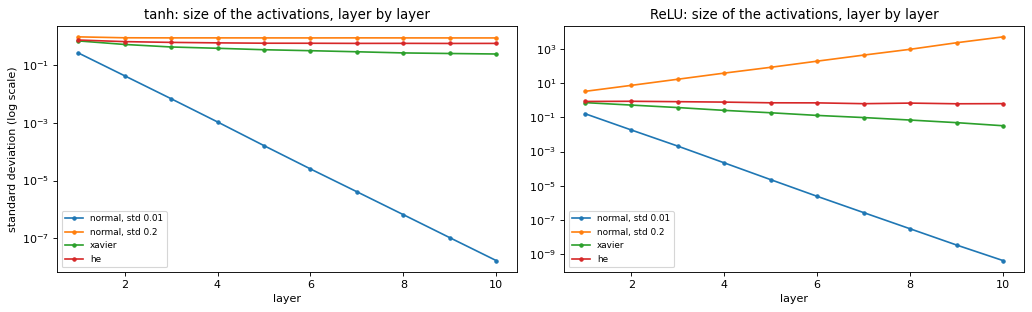

In [3]:
torch.manual_seed(0)
x = X_train[:512]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, act, name in [(axes[0], nn.Tanh, "tanh"), (axes[1], nn.ReLU, "ReLU")]:
    for scheme, std in [("normal", 0.01), ("normal", 0.2), ("xavier", None), ("he", None)]:
        m = init_network(make_mlp(hidden=(256,) * 10, activation=act), scheme, std)
        label = f"normal, std {std}" if scheme == "normal" else scheme
        ax.semilogy(range(1, 11), activation_sizes(m, x), marker="o", ms=3, label=label)
    ax.set_title(f"{name}: size of the activations, layer by layer"); ax.set_xlabel("layer"); ax.legend(fontsize=8)
axes[0].set_ylabel("standard deviation (log scale)")
plt.tight_layout()
plt.show()

**What we see.** The plot (log scale) shows the size of the signal after each of 10 layers, at the start of training:
- **std 0.01** (too small): the signal shrinks by a constant factor at every layer, to about $10^{-8}$ (tanh) and $10^{-9}$ (ReLU) at layer 10. The last layers see practically nothing of the image.
- **std 0.2** (too large): with **ReLU** the signal **grows** at every layer, to several thousand at layer 10, and training will explode. With **tanh** it cannot explode, because tanh squeezes everything into $(-1, 1)$, but most neurons then sit in the saturated region where gradients vanish (Notebook 06).
- **Xavier** keeps tanh nearly constant, but with ReLU it **slowly fades** (about twentyfold over 10 layers), because ReLU discards half of the signal at each layer.
- **He** keeps the ReLU signal flat from layer 1 to layer 10. The factor of 2 in its formula is exactly the correction for the half that ReLU discards.

## 3. Zeros: the symmetry problem

In [4]:
m = init_network(make_mlp(hidden=(128,)), "zeros")
h = fit(m, epochs=5)
first = m[0].weight.detach()
print("validation accuracy after 5 epochs with all-zero weights:", round(h["val acc"].iloc[-1], 4))
print("number of different rows among the 128 hidden neurons' weights:", torch.unique(first.round(decimals=6), dim=0).shape[0])

validation accuracy after 5 epochs with all-zero weights: 0.1014
number of different rows among the 128 hidden neurons' weights: 1


**What we see.** With all weights set to zero, the network stays at **10.1%** after 5 epochs, the level of random guessing, and all **128** hidden neurons have exactly the **same** weights (one distinct row). Every neuron starts identical, receives the identical gradient and makes the identical update, so they remain copies of each other forever: 128 neurons that behave as one. Random initialisation exists to **break this symmetry**.

## 4. Training a 10-layer ReLU network

Plain SGD (learning rate 0.05, no normalisation), 10 epochs, five initialisations.

In [5]:
rows = {}
for label, scheme, std in [("normal, std 0.01", "normal", 0.01), ("normal, std 0.2", "normal", 0.2), ("Xavier", "xavier", None),
                           ("He", "he", None), ("PyTorch default", None, None)]:
    torch.manual_seed(0)
    m = make_mlp(hidden=(256,) * 10)
    if scheme:
        init_network(m, scheme, std)
    h = fit(m, epochs=10, lr=0.05, optimizer="sgd")
    rows[label] = {"val acc after 1 epoch": h["val acc"].iloc[0], "after 10": h["val acc"].iloc[-1], "final train loss": h["train loss"].iloc[-1]}
pd.DataFrame(rows).T.round(3)

,val acc after 1 epoch,after 10,final train loss
"normal, std 0.01",0.101,0.101,2.302
"normal, std 0.2",0.099,0.099,NaN
Xavier,0.375,0.688,0.378
He,0.644,0.689,0.282
PyTorch default,0.106,0.101,2.302


**What we see.** Only the two scaled initialisations learn:
- **He** is the fastest start: **64.4%** after one epoch. **Xavier** starts more slowly (37.5%) because its signal fades through the ReLU layers, and catches up later; both reach about **69%** after 10 epochs. (Plain SGD with a high learning rate on a 10-layer network is noisy from epoch to epoch, which is why both are far below the 86% of a one-layer network with Adam; the training loss is lower with He, 0.28 against 0.38.)
- **std 0.01** stays at **10%** with the loss stuck at 2.302, which is $\ln 10$, the loss of a network that gives every class the same probability: the signal never reaches the output.
- **std 0.2** **explodes**: the loss becomes NaN (not a number) in the first epoch.
- **PyTorch's default also fails here** (10%, loss 2.302). Its default weights have a variance of about $1/(3n)$, six times smaller than He's $2/n$: fine for a few layers (every earlier notebook used it), but too small for 10 ReLU layers trained with plain SGD. This is the same failure seen in Notebook 06, Section 3.

## ⚠️ Common pitfalls

- **All weights equal** (zeros or any constant): every neuron in a layer learns the same thing.
- **A fixed standard deviation** such as 0.01 for every layer: fine for shallow networks, fatal for deep ones.
- **Xavier with ReLU in very deep networks:** the signal halves at each layer; use He.
- **Expecting the optimiser to fix a bad start.** Adam cannot rescue a signal that has already vanished in the forward pass (Exercise 1); normalisation layers can (Exercise 2), but the cause is still the initialisation.

## ✏️ Exercises

### Exercise 1 (Does Adam forgive?)
Train the 10-layer network with `normal, std 0.01` using **Adam** (learning rate 0.001) instead of SGD. Does it learn now?

In [6]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
torch.manual_seed(0)
m = init_network(make_mlp(hidden=(256,) * 10), "normal", 0.01)
h = fit(m, epochs=10, lr=1e-3, optimizer="adam")
print("std 0.01 with Adam: val acc", round(h["val acc"].iloc[-1], 4))
```

*It does not: in our run the network stays at about 10%, random guessing. Adam rescales tiny **gradients** into useful steps, but the problem here is in the **forward** pass: with std 0.01 the signal has practically vanished after a few layers (Section 2), so the output does not depend on the image and there is nothing useful for any optimiser to follow. A plausible guess ("Adam forgives poor initialisation") failed the experiment.*
</details>

### Exercise 2 (Does batch normalisation forgive?)
Train the same badly initialised 10-layer network (`std 0.01`, SGD, lr 0.05) with `batchnorm=True` in `make_mlp`. Compare with Section 4.

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
torch.manual_seed(0)
m = init_network(make_mlp(hidden=(256,) * 10, batchnorm=True), "normal", 0.01)
h = fit(m, epochs=10, lr=0.05, optimizer="sgd")
print("std 0.01 with batch normalisation: val acc", round(h["val acc"].iloc[-1], 4))
```

*Yes: in our run it reaches about **72%** after 10 epochs, where the same network without it stayed at 10%. Batch normalisation rescales every layer's output to a standard size, whatever the weights, so the signal can no longer vanish. It removes most of the sensitivity to initialisation; Notebook 10 looks at it in detail.*
</details>

## 🔑 Key takeaways

- Initial weights must be **random** (to break symmetry) and **well scaled** (to keep the signal alive through depth).
- **Xavier** suits tanh-like activations; **He** suits ReLU; both scale the variance by the number of inputs.
- PyTorch's default works for shallow networks and with Adam, which is why most people never notice the problem; for deep ReLU networks trained with SGD, set **He** initialisation explicitly.
- **Batch normalisation** makes training tolerant of poor initialisation; **Adam** alone does not, when the signal has already vanished.

---
**Next:** *Notebook 09: Regularisation*, dropout, weight decay and data augmentation against overfitting.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*